In [1]:
import pandas as pd
import os
import sys
from datetime import datetime, timedelta
from collections import defaultdict
import glob
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Get the current working directory
current_dir = os.getcwd()
# Go up one level to reach the root directory (ML4Processes)
root_dir = os.path.abspath(os.path.join(current_dir, ".."))
# Add the root directory to the Python path
if root_dir not in sys.path:
    sys.path.append(root_dir)

from utils.helper import read_json, write_json

In [8]:
def create_heatmaps(df_dict):
    """
    Creates 4 heatmaps side by side for comparing different datasets with a single legend
    
    Args:
        df_dict: Dictionary with keys as plot titles and values as dataframes
    """
    # Create a figure with 4 subplots
    fig, axes = plt.subplots(1, len(df_dict), figsize=(40, 8))
    
    # # Create a figure with 4 subplots in 2x2 layout
    # fig, axes = plt.subplots(2, 2, figsize=(20, 16))  # Adjusted figure size for 2x2 layout
    # axes = axes.flatten()  # Flatten the 2x2 array to make it easier to iterate

    # Define constants
    ordered_days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
    full_hours = list(range(24))
    
    # Track the maximum value across all datasets for consistent color scaling
    max_value = 0
    all_heatmap_data = []
    max_values = []
    
    # First pass to get max value for consistent color scaling
    for df in df_dict.values():
        arrival_times_df = pd.DataFrame(df, columns=['arrival_time'])
        arrival_times_df['hour'] = arrival_times_df['arrival_time'].dt.hour
        arrival_times_df['day_of_week'] = arrival_times_df['arrival_time'].dt.day_name()
        
        heatmap_data = arrival_times_df.pivot_table(
            index='hour',
            columns='day_of_week',
            aggfunc='size',
            fill_value=0
        ).reindex(index=full_hours, columns=ordered_days, fill_value=0)
        
        max_value = heatmap_data.values.max()
        max_values.append(max_value)
        all_heatmap_data.append(heatmap_data)
    
    # Create the heatmaps
    for i, ((title, df), ax, heatmap_data) in enumerate(zip(df_dict.items(), axes, all_heatmap_data)):
        # Create heatmap
        im = sns.heatmap(heatmap_data, cmap='Reds', annot=False, fmt='d', 
                        linewidths=.5, ax=ax, vmin=0, vmax=max_values[i],
                        cbar=True if i == len(df_dict)-1 else False)  # Only show colorbar for last plot
        # # please get rid of the labels in the plot
        ax.set_xticks([])
        ax.set_yticks([])

        # remove x and y labels
        ax.set_xlabel('')
        ax.set_ylabel('')
      
    # Adjust layout to make room for the colorbar
    plt.tight_layout()
    plt.show()

File correctly read: ../event_log_simulations/best_distribution_prob/BPI_Challenge_2012/test.json.
Number of events Test Data: 2618
File correctly read: ../event_log_simulations/kde_prob/BPI_Challenge_2012/simulated_run_1.json.
Number of events KDE: 2791
File correctly read: ../event_log_simulations/prophet/BPI_Challenge_2012/simulated_run_1.json.
Number of events Prophet: 2324
File correctly read: ../event_log_simulations/best_distribution_prob/BPI_Challenge_2012/simulated_run_1.json.
Number of events Best Distribution: 2292
File correctly read: ../event_log_simulations/lstm/BPI_Challenge_2012/simulated_run_1.json.
Number of events LSTM: 2236
File correctly read: ../event_log_simulations/xgboost/BPI_Challenge_2012/simulated_run_1.json.
Number of events XGBoost: 2438
File correctly read: ../event_log_simulations/chronos/BPI_Challenge_2012/simulated_run_1.json.
Number of events Chronos: 1782


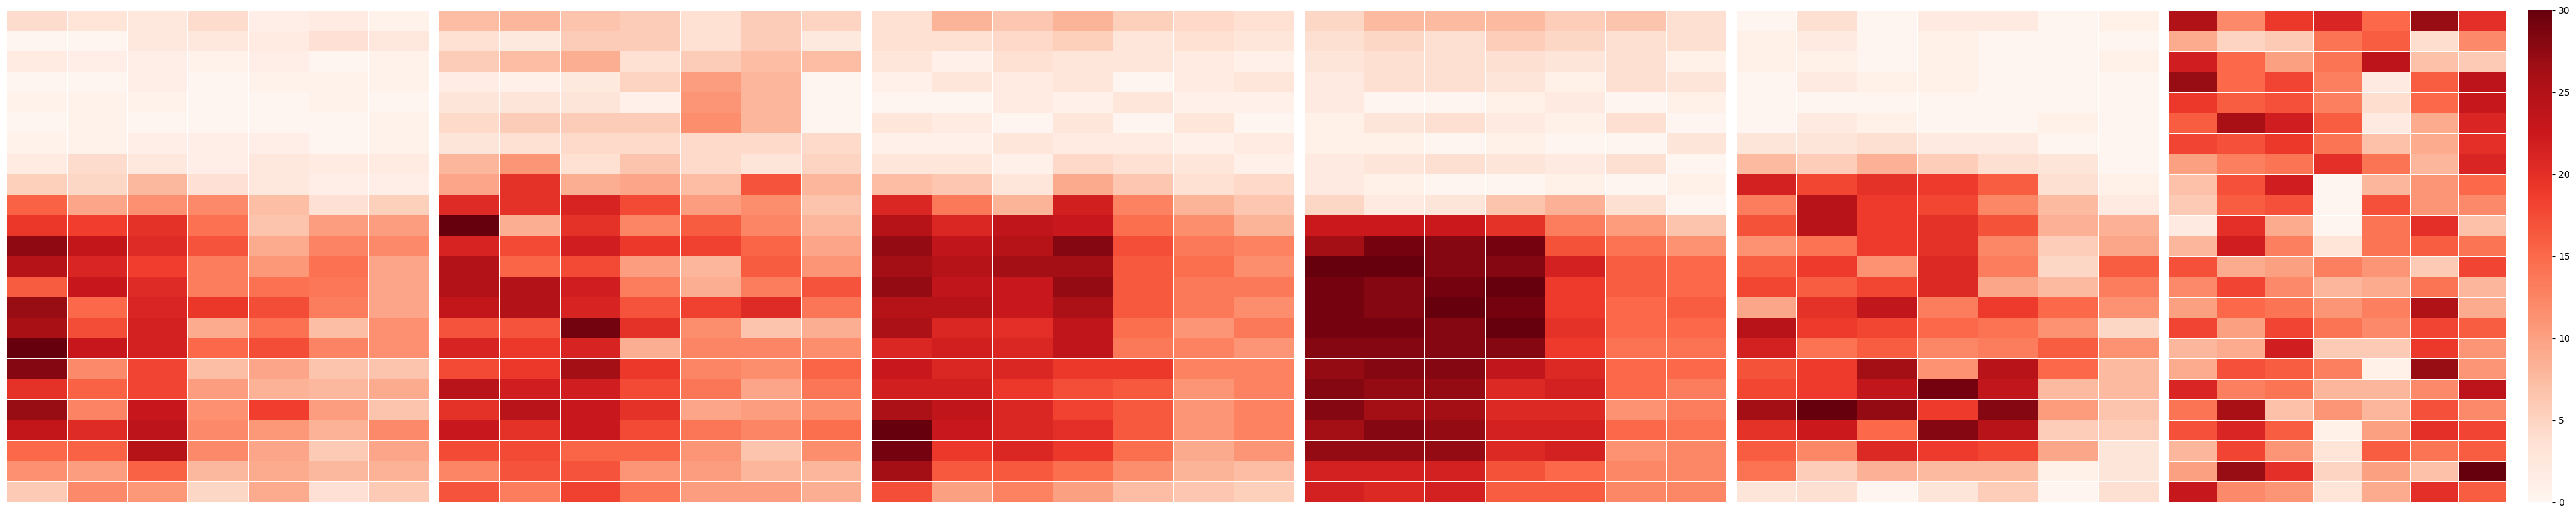

In [11]:
test_timestamps_list = [read_json(('../event_log_simulations/best_distribution_prob/BPI_Challenge_2012/test.json'))]
test_df = pd.DataFrame({'arrival_time':test_timestamps_list[0]})
test_df['arrival_time'] = pd.to_datetime(test_df['arrival_time'], format = "%d.%m.%Y %H:%M:%S")
print(f"Number of events Test Data: {len(test_df)}")

kde_list = [read_json('../event_log_simulations/kde_prob/BPI_Challenge_2012/simulated_run_1.json')]
kde = pd.DataFrame({'arrival_time':kde_list[0]})
kde['arrival_time'] = pd.to_datetime(kde['arrival_time'], format = "%d.%m.%Y %H:%M:%S")
print(f"Number of events KDE: {len(kde)}")
prophet_list = [read_json('../event_log_simulations/prophet/BPI_Challenge_2012/simulated_run_1.json')]
prophet = pd.DataFrame({'arrival_time':prophet_list[0]})
prophet['arrival_time'] = pd.to_datetime(prophet['arrival_time'], format = "%d.%m.%Y %H:%M:%S")
print(f"Number of events Prophet: {len(prophet)}")
best_dist_list = [read_json('../event_log_simulations/best_distribution_prob/BPI_Challenge_2012/simulated_run_1.json')]
best_dist = pd.DataFrame({'arrival_time':best_dist_list[0]})
best_dist['arrival_time'] = pd.to_datetime(best_dist['arrival_time'], format = "%d.%m.%Y %H:%M:%S")
print(f"Number of events Best Distribution: {len(best_dist)}")
lstm_list = [read_json('../event_log_simulations/lstm/BPI_Challenge_2012/simulated_run_1.json')]
lstm = pd.DataFrame({'arrival_time':lstm_list[0]})
lstm['arrival_time'] = pd.to_datetime(lstm['arrival_time'], format = "%d.%m.%Y %H:%M:%S")
print(f"Number of events LSTM: {len(lstm)}")
xgboost_list = [read_json('../event_log_simulations/xgboost/BPI_Challenge_2012/simulated_run_1.json')]
xgboost = pd.DataFrame({'arrival_time':xgboost_list[0]})
xgboost['arrival_time'] = pd.to_datetime(xgboost['arrival_time'], format = "%d.%m.%Y %H:%M:%S")
print(f"Number of events XGBoost: {len(xgboost)}")

chronos_list = [read_json('../event_log_simulations/chronos/BPI_Challenge_2012/simulated_run_1.json')]
chronos = pd.DataFrame({'arrival_time':chronos_list[0]})
chronos['arrival_time'] = pd.to_datetime(chronos['arrival_time'], format = "%d.%m.%Y %H:%M:%S")
print(f"Number of events Chronos: {len(chronos)}")


df_dict = {
    'Test Data': test_df,
    'KDE': kde,
    'LSTM': lstm,
    'XGBoost': xgboost,
    'Chronos': chronos,
    
    # 'Prophet': prophet,
    'Best Distribution': best_dist,
    
}
create_heatmaps(df_dict)

In [14]:
import numpy as np
train_time = [5.58220100402832, 3.5255141258239746, 2.99663, 46.8157, 27.49511885, 2.5448570, 1.70890188, 27.055854, 21.5731, 18.28251, 9.673657, 20.59327, 4.14157, 36.632, 14.5530, 4.25722, 12.2874, 220.24346, 3.646631]
print(np.mean(train_time), np.std(train_time))

sim_time = [11.43352, 3.6046, 5.16824, 136.40, 5.39683, 2693.873, 0.762346, 134.87039, 36.6328, 28.550945, 1227.625, 36.58233, 0.09515, 8.9585828, 8.50059, 4.538393, 26.63985, 2038.7561, 5.0484719]
print(np.mean(sim_time), np.std(sim_time))

25.453083939992226 47.57823906977947
337.54932308947366 753.8354122265087
